In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

import os
import copy
import json
import glob
from PIL import Image
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from typing import Dict, Any

from transformers import AutoImageProcessor, AutoModel
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# --- НАСТРОЙКИ ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SOURCE_IMAGES_DIR = "data/dataset"
ANNOTATIONS_DIR = "data/annotations"
DINOV3_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
MODEL_FILTER = "gemini"

In [4]:
# Гиперпараметры обучения
BATCH_SIZE = 32
LEARNING_RATE = 3e-4 # Можно начать с чуть большего LR для регрессии
NUM_EPOCHS = 100
VAL_SPLIT = 0.2

In [5]:
TARGET_COLUMNS = ['hollows', 'cracks', 'stem_damage', 'crown_damage', 'fruiting_bodies', 'dry_branches_percentage']

print(f"Используемое устройство: {DEVICE}")

Используемое устройство: cuda


In [6]:
def load_feature_extractor() -> Dict[str, Any]:
    models = {}
    print(f"Загрузка DINOv3 ({DINOV3_ID})...")
    models['processor'] = AutoImageProcessor.from_pretrained(DINOV3_ID)
    models['model'] = AutoModel.from_pretrained(DINOV3_ID).to(DEVICE)
    models['model'].eval()
    return models

In [7]:
feature_extractor_models = load_feature_extractor()
EMBEDDING_DIM = feature_extractor_models['model'].config.hidden_size
print(f"Размерность эмбеддинга: {EMBEDDING_DIM}")

Загрузка DINOv3 (facebook/dinov3-vits16-pretrain-lvd1689m)...
Размерность эмбеддинга: 384


In [8]:
def create_dataframe_from_annotations(ann_dir, img_dir, model_filter):
    json_files = glob.glob(os.path.join(ann_dir, "*.json"))
    data_records = []

    for json_path in tqdm(json_files, desc="Чтение аннотаций"):
        with open(json_path, 'r', encoding='utf-8') as f:
            data = json.load(f)

        if data.get("model_name") != model_filter:
            continue

        img_path = os.path.join(img_dir, data.get("img_path"))
        if not os.path.exists(img_path):
            continue

        for ann in data.get("annotations", []):
            record = {
                'image_path': img_path,
                'bbox': ann.get('bbox')
            }
            # Собираем все целевые переменные
            has_all_targets = True
            for col in TARGET_COLUMNS:
                value = ann.get(col)
                if value is None:
                    has_all_targets = False
                    break
                # Нормализуем 'dry_branches_percentage' в диапазон [0, 1]
                record[col] = float(value) / 100.0 if col == 'dry_branches_percentage' else float(value)
            
            # Добавляем запись, только если все таргеты присутствуют
            if has_all_targets:
                data_records.append(record)

    return pd.DataFrame(data_records)

In [9]:
df_characteristics = create_dataframe_from_annotations(ANNOTATIONS_DIR, SOURCE_IMAGES_DIR, MODEL_FILTER)
print(f"\nСоздан DataFrame с {len(df_characteristics)} записями.")
df_characteristics.head()

Чтение аннотаций:   0%|          | 0/361 [00:00<?, ?it/s]


Создан DataFrame с 434 записями.


,image_path,bbox,hollows,cracks,stem_damage,crown_damage,fruiting_bodies,dry_branches_percentage
0,data/dataset\08yitoAmovM.jpg,"[10, 0, 284, 998]",0.00,0.00,0.00,0.00,0.0,0.15
1,data/dataset\08yitoAmovM.jpg,"[75, 510, 185, 955]",0.00,0.00,0.00,0.00,0.0,0.10
2,data/dataset\08yitoAmovM_obj1_a tree_0.449.jpg,"[0, 0, 280, 987]",0.00,0.00,0.93,0.81,0.0,0.15
3,data/dataset\0cWwTCAiBaE.jpg,"[0, 0, 1200, 959]",0.00,0.82,0.88,0.00,0.0,0.00
4,data/dataset\0cWwTCAiBaE_obj1_a tree_0.754.jpg,"[0, 0, 1191, 1389]",0.81,0.84,0.93,0.00,0.0,0.00


In [12]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [13]:
class CharacteristicsDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform
        # Извлекаем таргеты в numpy массив для скорости
        self.targets = self.df[TARGET_COLUMNS].values.astype(np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['image_path']
        bbox = row['bbox']
        targets = self.targets[idx]
        
        try:
            image = Image.open(img_path).convert("RGB")
            # --- Вырезаем объект по bbox ПЕРЕД аугментацией ---
            cropped_image = image.crop(tuple(bbox))
            
            if self.transform:
                image_tensor = self.transform(cropped_image)
        except Exception as e:
            print(f"Ошибка при загрузке/обрезке {img_path}: {e}")
            return torch.zeros(3, 224, 224), torch.zeros(len(TARGET_COLUMNS))

        return image_tensor, torch.from_numpy(targets)

In [14]:
full_dataset = CharacteristicsDataset(df_characteristics)

# --- Разделение на train/val ---
val_size = int(VAL_SPLIT * len(full_dataset))
train_size = len(full_dataset) - val_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# Применяем трансформации
train_dataset_final = copy.deepcopy(train_subset)
train_dataset_final.dataset.transform = train_transforms
val_dataset_final = copy.deepcopy(val_subset)
val_dataset_final.dataset.transform = val_transforms

# --- Создание DataLoader'ов ---
train_loader = DataLoader(train_dataset_final, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset_final, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Обучающая выборка: {len(train_dataset_final)}")
print(f"Валидационная выборка: {len(val_dataset_final)}")

Обучающая выборка: 348
Валидационная выборка: 86


In [15]:
class RegressionModel(nn.Module):
    def __init__(self, embedding_dim, output_dim, hidden_dim=256, dropout_rate=0.4):
        super(RegressionModel, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid() # Sigmoid на выходе, чтобы значения были в диапазоне [0, 1]
        )

    def forward(self, x):
        return self.layers(x)

# Инициализация модели
regression_model = RegressionModel(EMBEDDING_DIM, len(TARGET_COLUMNS)).to(DEVICE)
print(regression_model)

RegressionModel(
  (layers): Sequential(
    (0): Linear(in_features=384, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=6, bias=True)
    (5): Sigmoid()
  )
)


In [16]:
# --- Обучение ---
criterion = nn.SmoothL1Loss() # SmoothL1Loss хорошо работает для регрессии, более устойчив к выбросам, чем MSE
optimizer = torch.optim.AdamW(regression_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.2, patience=5)

best_val_loss = float('inf')

for epoch in range(NUM_EPOCHS):
    # --- Тренировочный шаг ---
    regression_model.train()
    running_loss = 0.0
    
    for images, targets in tqdm(train_loader, desc=f"Эпоха {epoch+1}/{NUM_EPOCHS} [Train]"):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        
        with torch.no_grad():
            embeddings = feature_extractor_models['model'](images).last_hidden_state[:, 0, :]
            
        optimizer.zero_grad()
        outputs = regression_model(embeddings)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_loader.dataset)

    # --- Валидационный шаг ---
    regression_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            
            embeddings = feature_extractor_models['model'](images).last_hidden_state[:, 0, :]
            outputs = regression_model(embeddings)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * images.size(0)
    
    val_loss /= len(val_loader.dataset)
    scheduler.step(val_loss) # Шаг шедулера по валидационной потере
    
    print(f"Эпоха {epoch+1}/{NUM_EPOCHS} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f}")

    # Сохраняем лучшую модель
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(regression_model.state_dict(), "best_characteristics_model.pth")
        print(f"  -> Модель сохранена (Val Loss улучшилась до {best_val_loss:.4f})")

print("\nОбучение завершено.")

Эпоха 1/100 [Train]:   0%|          | 0/11 [00:00<?, ?it/s]

Эпоха 1/100 | Train Loss: 0.0925 | Val Loss: 0.0832
  -> Модель сохранена (Val Loss улучшилась до 0.0832)


Эпоха 2/100 [Train]:   0%|          | 0/11 [00:00<?, ?it/s]

Эпоха 2/100 | Train Loss: 0.0669 | Val Loss: 0.0652
  -> Модель сохранена (Val Loss улучшилась до 0.0652)


Эпоха 3/100 [Train]:   0%|          | 0/11 [00:00<?, ?it/s]

...

Эпоха 40/100 | Train Loss: 0.0175 | Val Loss: 0.0313


Эпоха 41/100 [Train]:   0%|          | 0/11 [00:00<?, ?it/s]

Эпоха 41/100 | Train Loss: 0.0174 | Val Loss: 0.0313


Эпоха 42/100 [Train]:   0%|          | 0/11 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [34]:
# --- Тестирование ---
best_model = RegressionModel(EMBEDDING_DIM, len(TARGET_COLUMNS))
best_model.load_state_dict(torch.load("best_characteristics_model.pth"))
best_model.to(DEVICE)
best_model.eval()

all_targets = []
all_preds = []

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Тестирование"):
        images = images.to(DEVICE)
        
        embeddings = feature_extractor_models['model'](images).last_hidden_state[:, 0, :]
        outputs = best_model(embeddings)
        
        all_targets.append(targets.cpu().numpy())
        all_preds.append(outputs.cpu().numpy())

# Объединяем результаты из всех батчей
all_targets = np.concatenate(all_targets)
all_preds = np.concatenate(all_preds)

Тестирование:   0%|          | 0/3 [00:00<?, ?it/s]


--- Отчет по метрикам на валидационной выборке ---
Характеристика            | MAE        | RMSE       | R² Score  
-----------------------------------------------------------------
hollows                   | 0.182      | 0.267      | 0.3804    
cracks                    | 0.137      | 0.219      | 0.4001    
stem_damage               | 0.245      | 0.313      | 0.4004    
crown_damage              | 0.267      | 0.331      | 0.1358    
fruiting_bodies           | 0.085      | 0.121      | -0.0493   
dry_branches_percentage   | 11.239    % | 17.152    % | 0.1712    


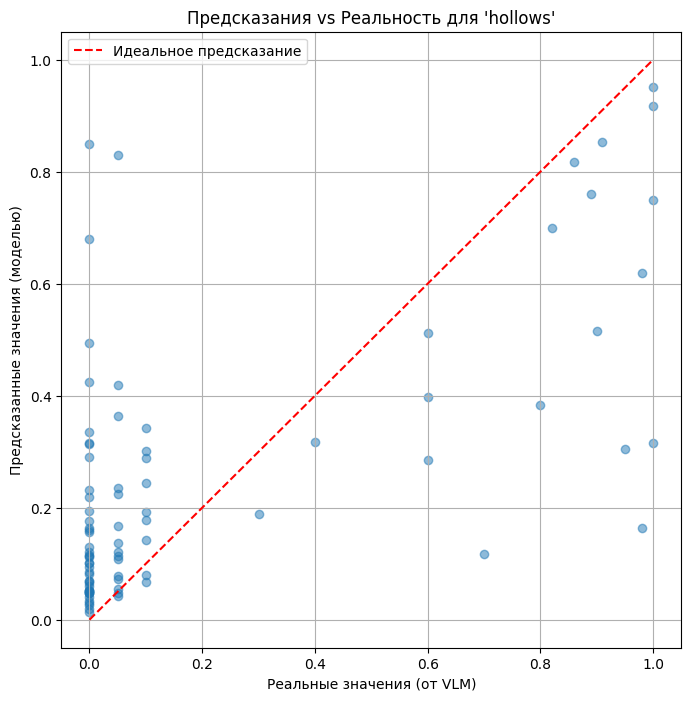

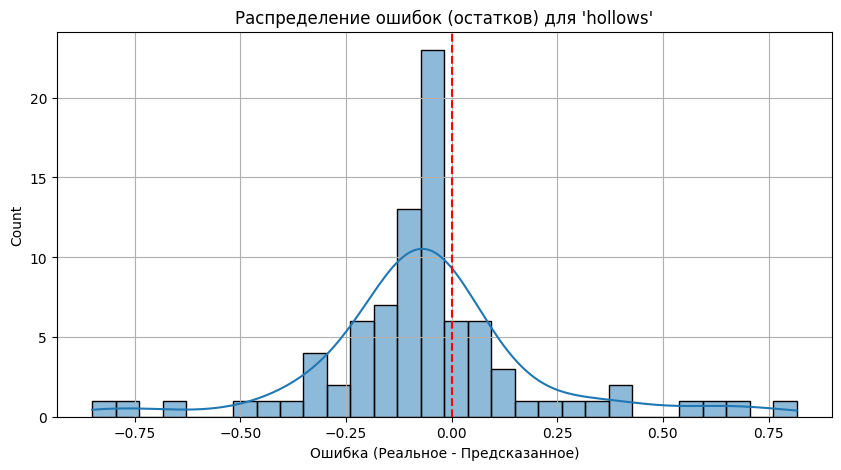

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Расширенный отчет по метрикам ---
print("\n--- Отчет по метрикам на валидационной выборке ---")
print(f"{'Характеристика':<25} | {'MAE':<10} | {'RMSE':<10} | {'R² Score':<10}")
print("-" * 65)

results_summary = {}

for i, col_name in enumerate(TARGET_COLUMNS):
    targets_col = all_targets[:, i]
    preds_col = all_preds[:, i]
    
    # Для dry_branches_percentage масштабируем обратно в проценты
    if col_name == 'dry_branches_percentage':
        targets_col *= 100
        preds_col *= 100
        unit = "%"
    else:
        unit = ""
        
    mae = mean_absolute_error(targets_col, preds_col)
    rmse = np.sqrt(mean_squared_error(targets_col, preds_col))
    r2 = r2_score(targets_col, preds_col)
    
    results_summary[col_name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    
    print(f"{col_name:<25} | {mae:<10.3f}{unit} | {rmse:<10.3f}{unit} | {r2:<10.4f}")

# --- Визуализация ---
# График "Предсказания vs Реальность"
feature_to_plot = 'hollows'
feature_idx = TARGET_COLUMNS.index(feature_to_plot)
plt.figure(figsize=(8, 8))
plt.scatter(all_targets[:, feature_idx], all_preds[:, feature_idx], alpha=0.5)
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Идеальное предсказание')
plt.title(f"Предсказания vs Реальность для '{feature_to_plot}'")
plt.xlabel("Реальные значения (от VLM)")
plt.ylabel("Предсказанные значения (моделью)")
plt.grid(True)
plt.legend()
plt.show()

# График остатков (ошибок)
residuals = all_targets[:, feature_idx] - all_preds[:, feature_idx]
plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.title(f"Распределение ошибок (остатков) для '{feature_to_plot}'")
plt.xlabel("Ошибка (Реальное - Предсказанное)")
plt.axvline(0, color='red', linestyle='--')
plt.grid(True)
plt.show()


--- Отчет по метрикам бинарной классификации (порог = 0.5) ---
         Характеристика  Accuracy  Precision  Recall  F1-score  Support (кол-во)
                hollows    0.8837     0.7692  0.5882    0.6667                17
                 cracks    0.9070     0.6250  0.5000    0.5556                10
            stem_damage    0.7791     0.6471  0.7586    0.6984                29
           crown_damage    0.7326     0.5833  0.5185    0.5490                27
        fruiting_bodies    0.9651     0.0000  0.0000    0.0000                 3
dry_branches_percentage    0.8372     0.8372  1.0000    0.9114                72


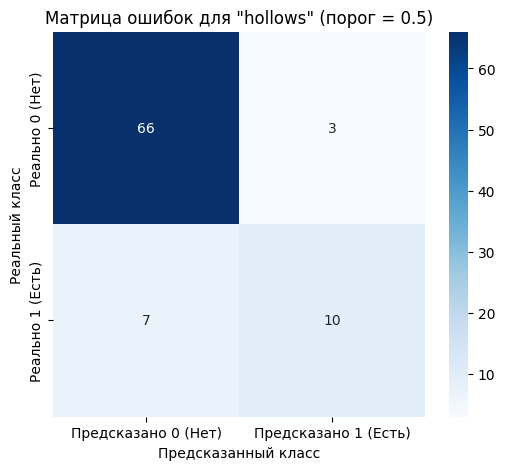


Детализация для 'hollows':
  - True Positive (TP - правильно найденные): 10
  - True Negative (TN - правильно пропущенные): 66
  - False Positive (FP - ложные срабатывания): 3
  - False Negative (FN - пропущенные признаки): 7


In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# --- Расчет метрик бинарной классификации ---

# Порог для преобразования вероятностей в классы (0 или 1)
THRESHOLD = 0.5

print(f"\n--- Отчет по метрикам бинарной классификации (порог = {THRESHOLD}) ---")

# Список для хранения результатов
classification_results = []

for i, col_name in enumerate(TARGET_COLUMNS):
    # Получаем исходные вероятности
    targets_prob = all_targets[:, i]
    preds_prob = all_preds[:, i]
    
    # Применяем порог для получения бинарных меток
    # Для dry_branches_percentage порог будет 0.5, так как мы его нормализовали в [0, 1]
    targets_binary = (targets_prob >= THRESHOLD).astype(int)
    preds_binary = (preds_prob >= THRESHOLD).astype(int)
    
    # Считаем метрики
    accuracy = accuracy_score(targets_binary, preds_binary)
    # average='binary' подходит, когда нас интересует только класс '1' (наличие признака)
    # zero_division=0 предотвращает ошибку, если в предсказаниях или метках нет положительного класса
    precision = precision_score(targets_binary, preds_binary, average='binary', zero_division=0)
    recall = recall_score(targets_binary, preds_binary, average='binary', zero_division=0)
    f1 = f1_score(targets_binary, preds_binary, average='binary', zero_division=0)
    
    # Подсчитываем количество положительных примеров в валидационной выборке
    support = np.sum(targets_binary)
    
    classification_results.append({
        'Характеристика': col_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Support (кол-во)': support
    })

# Создаем DataFrame для красивого вывода
results_df = pd.DataFrame(classification_results)
print(results_df.to_string(index=False, float_format="%.4f"))


# --- Визуализация матрицы ошибок для одного из признаков ---
feature_to_plot = 'hollows'
feature_idx = TARGET_COLUMNS.index(feature_to_plot)

# Получаем бинарные метки для выбранного признака
targets_binary_plot = (all_targets[:, feature_idx] >= THRESHOLD).astype(int)
preds_binary_plot = (all_preds[:, feature_idx] >= THRESHOLD).astype(int)

# Строим матрицу ошибок
cm = confusion_matrix(targets_binary_plot, preds_binary_plot)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Предсказано 0 (Нет)', 'Предсказано 1 (Есть)'], 
            yticklabels=['Реально 0 (Нет)', 'Реально 1 (Есть)'])
plt.title(f'Матрица ошибок для "{feature_to_plot}" (порог = {THRESHOLD})')
plt.ylabel('Реальный класс')
plt.xlabel('Предсказанный класс')
plt.show()

# Выводим TP, TN, FP, FN для наглядности
tn, fp, fn, tp = cm.ravel()
print(f"\nДетализация для '{feature_to_plot}':")
print(f"  - True Positive (TP - правильно найденные): {tp}")
print(f"  - True Negative (TN - правильно пропущенные): {tn}")
print(f"  - False Positive (FP - ложные срабатывания): {fp}")
print(f"  - False Negative (FN - пропущенные признаки): {fn}")